# Homework 2: Statistical inference

Predict what will change, then move the slider and check. Explore the data, then complete the `TODO` functions and write your reasoning below each experiment. If a slider is unavailable, change `start` and rerun the cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import beta, norm, t
from IPython.display import display

try:
    from ipywidgets import SelectionSlider
except ImportError:
    SelectionSlider = None

R = 5000
BLUE, ORANGE, GREEN, INK = '#206894', '#bb4d28', '#16826f', '#293946'
plt.rcParams.update({'figure.dpi': 105, 'font.size': 10, 'axes.titlesize': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False})

def explore(draw, choices, start, label, preview=None):
    try:
        fig = draw(start)
    except NotImplementedError as missing:
        if preview is None:
            print(f'Complete {missing} above, then rerun this cell.')
            return
        print('Explore the data now. Complete the functions above and rerun for the full experiment.')
        draw = preview
        fig = draw(start)
    if SelectionSlider is None:
        display(fig)
        plt.close(fig)
        return
    slider = SelectionSlider(options=choices, value=start, description=label,
                             continuous_update=False, style={'description_width': 'initial'})
    display(slider)
    picture = display(fig, display_id=True)
    plt.close(fig)
    def redraw(change):
        fig = draw(change['new'])
        picture.update(fig)
        plt.close(fig)
    slider.observe(redraw, names='value')

## 1. How many requests are enough?

Independent request times are exponential with mean 1 second. We want the sample mean to miss 1 by more than ε seconds in at most 5% of datasets.

1. Use Chebyshev and the CLT to choose sample sizes for ε = 0.25. Which choice guarantees the target?
2. Predict how those sizes change if you halve ε. In the first plot, follow one running average as requests arrive. In the second, compare the miss rate across independent datasets with the 5% target.

In [2]:
def latency_paths(eps):
    rng = np.random.default_rng(21)
    n = np.arange(1, 321)
    paths = rng.exponential(size=(6, n.size)).cumsum(axis=1) / n
    fig, ax = plt.subplots(figsize=(7.6, 3), layout='constrained')
    ax.axhspan(1-eps, 1+eps, color=GREEN, alpha=.14, label='Within tolerance')
    for j, path in enumerate(paths):
        ax.plot(n, path, color=BLUE if j == 0 else '#8b9eaa',
                lw=2 if j == 0 else .85, alpha=1 if j == 0 else .7)
    ax.axhline(1, color=INK, ls='--', lw=1)
    ax.set(xscale='log', xlabel='Requests observed', ylabel='Running mean (seconds)',
           title='Six sequences of requests', xticks=[1, 5, 20, 80, 320],
           xticklabels=['1','5','20','80','320'])
    ax.legend()
    return fig

SelectionSlider(continuous_update=False, description='Tolerance (s)', index=1, options=(0.125, 0.25, 0.5), sty…

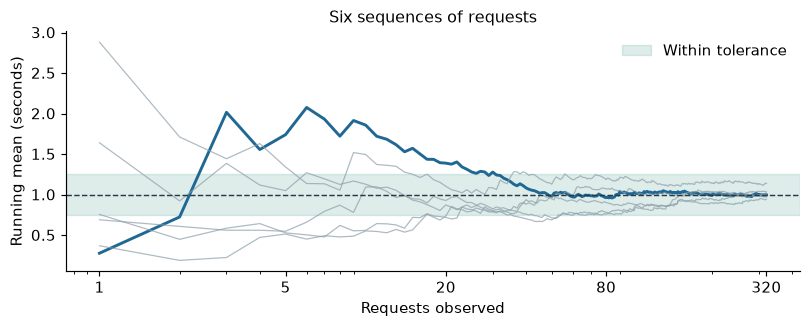

In [3]:
explore(latency_paths, [0.125, 0.25, 0.5], start=0.25, label='Tolerance (s)')

In [4]:
def latency_sizes(tolerance, alpha):
    z = norm.ppf(1 - alpha / 2)
    # TODO: Return integer sizes (Chebyshev, CLT). Round up.
    raise NotImplementedError('latency_sizes')

def miss_rate(means, tolerance):
    # TODO: Return the fraction of sample means outside the tolerance band.
    raise NotImplementedError('miss_rate')

In [5]:
def latency_risk(eps):
    n_bound, n_clt = latency_sizes(eps, 0.05)
    sizes = np.unique(np.r_[np.geomspace(3, n_bound, 35).astype(int), n_clt, n_bound])
    rng = np.random.default_rng(201)
    # The sum of n independent Exp(1) times is Gamma(shape=n, scale=1).
    misses = [miss_rate(rng.gamma(n, size=R) / n, eps) for n in sizes]
    fig, ax = plt.subplots(figsize=(7.6, 3.1), layout='constrained')
    ax.plot(sizes, 100*np.array(misses), '.-', color=BLUE, label='Simulation')
    ax.axhline(5, ls=':', color=INK, label='5% target')
    for n, color, name in [(n_clt, ORANGE, 'CLT'), (n_bound, GREEN, 'Chebyshev')]:
        ax.axvline(n, ls='--', color=color, label=f'{name}: n = {n}')
    ax.set(xscale='log', xlabel='Requests per dataset', ylabel='Datasets outside band (%)',
           title=f'Missing the target by more than {eps:g} seconds', ylim=(-1, None))
    ax.legend(loc='upper center', fontsize=9)
    return fig

In [6]:
explore(latency_risk, [0.125, 0.25, 0.5], start=0.25, label='Tolerance (s)')

Complete latency_sizes above, then rerun this cell.


*Answer:*

## 2. Can an estimate rule out a delay you just observed?

Delays are independent and uniform on $[0,\theta]$. Write $M=\max_i X_i$.

1. Derive the moment estimator and the MLE. Use $P(M\le m)=(m/\theta)^n$ to find a constant $c_n$ such that $c_nM$ is unbiased.
2. At $\theta=10$, compare all three estimates on the same samples. Which can fall below an observed delay? Predict which has the smallest MSE, then change $n$ from 5 to 100. Use the error distributions to explain your choice.

In [7]:
def delay_estimates(samples):
    n = samples.shape[1]
    # TODO: Return three arrays, one value per row: moments, MLE, corrected maximum.
    raise NotImplementedError('delay_estimates')

In [8]:
def delay_data(n):
    x = np.random.default_rng(202).uniform(0, 10, (5, n))
    fig, ax = plt.subplots(figsize=(7.6, 2.7), layout='constrained')
    for row, sample in enumerate(x, 1):
        ax.scatter(sample, np.full(n, row), marker='|', s=90, color=BLUE, alpha=.75)
    ax.axvline(10, ls=':', color=INK, label='True limit')
    ax.set(xlabel='Observed delay (seconds)', ylabel='Dataset', yticks=range(1,6),
           ylim=(.5,5.5), xlim=(0,11), title=f'Five samples of {n} delays')
    ax.legend(loc='center right', bbox_to_anchor=(1,.6))
    return fig

def delay_plot(n):
    rng = np.random.default_rng(202)
    theta = 10
    x = rng.uniform(0, theta, (R, n))
    estimates = delay_estimates(x)
    fig, (raw, errors) = plt.subplots(1, 2, figsize=(9.3, 3.5), layout='constrained')
    raw.scatter(x[0], np.zeros(n), marker='|', s=140, color=INK)
    names = ['Moments', 'Maximum', 'Corrected max']
    colors = [BLUE, ORANGE, GREEN]
    edges = np.histogram_bin_edges(np.concatenate(estimates) - theta, bins=50)
    for row, (values, name, color) in enumerate(zip(estimates, names, colors), 1):
        raw.scatter(values[0], row, s=45, color=color)
        err = values - theta
        errors.hist(err, bins=edges, histtype='step', density=True, lw=1.8, color=color,
                    label=f'{name}  ·  MSE {np.mean(err**2):.2f}')
    raw.axvline(theta, color=INK, ls=':', label='True limit')
    raw.set(yticks=range(4), yticklabels=['Delays']+names, xlabel='Delay (seconds)',
            ylim=(-.6, 3.6), xlim=(0, max(11, *(v[0]+.5 for v in estimates))), title='One dataset')
    raw.legend(loc='upper left', fontsize=8)

    errors.axvline(0, color=INK, ls=':')
    errors.set(xlabel='Estimate minus true limit (seconds)', ylabel='Density',
               title=f'{R:,} datasets, n = {n}')
    errors.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1,1.01), frameon=True, facecolor='white', edgecolor='none', framealpha=.94)
    return fig

Explore the data now. Complete the functions above and rerun for the full experiment.


SelectionSlider(continuous_update=False, description='Delays per dataset', options=(5, 20, 100), style=SliderS…

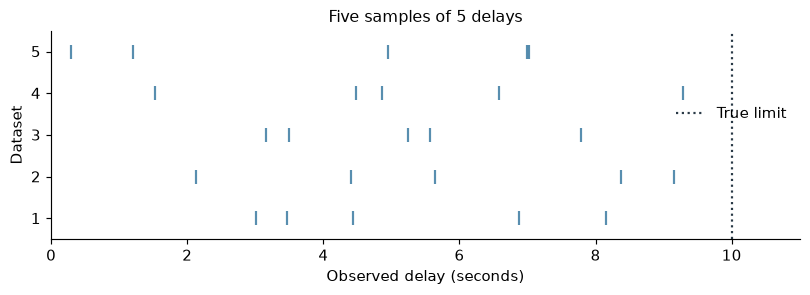

In [9]:
explore(delay_plot, [5, 20, 100], start=5, label='Delays per dataset', preview=delay_data)

*Answer:*

## 3. When does a prior help?

Each of $n$ independent tests fails with probability $p$. Use a $\mathrm{Beta}(2,18)$ prior.

1. Derive the MLE and MAP after $k$ failures. With zero failures, predict where the posterior peak will move when $n$ increases from 20 to 200.
2. Find one true failure rate where MAP lowers MSE and one where it raises MSE. Use the curves to estimate where the ordering changes. Explain why the same prior can give both results.

In [10]:
def failure_estimates(k, n):
    # TODO: Return the MLE and MAP for a failure count (or an array of counts).
    raise NotImplementedError('failure_estimates')

In [11]:
def failure_data(n):
    p = np.linspace(0, .32, 401)
    fig, ax = plt.subplots(figsize=(7.6, 2.8), layout='constrained')
    ax.plot(p, (1-p)**n, color=BLUE)
    ax.set(xlabel='True failure probability', ylabel='Probability of zero failures',
           title=f'How likely is a clean run of {n} tests?', ylim=(-.02,1.03))
    return fig

def prior_plot(n):
    mle0, map0 = failure_estimates(0, n)
    rng = np.random.default_rng(203)
    rates = np.linspace(.01, .40, 79)
    counts = rng.binomial(n, rates, size=(R, len(rates)))
    mle, map_est = failure_estimates(counts, n)
    fig, (post, risk) = plt.subplots(1, 2, figsize=(9.3, 3.45), layout='constrained')
    p = np.linspace(0, .32, 1000)
    for density, label, color in [(beta.pdf(p, 2, 18), 'Prior', BLUE),
                                  (beta.pdf(p, 2, n+18), 'Posterior', GREEN)]:
        post.plot(p, density, color=color, label=label)
    post.axvline(map0, color=GREEN, ls=':', label=f'MAP {map0:.1%}')
    post.scatter([mle0], [0], marker='D', color=ORANGE, zorder=3, label='MLE')
    post.set(xlabel='Failure probability', ylabel='Density', title=f'Zero failures in {n} tests')
    post.legend(fontsize=8)
    for est, label, color in [(mle, 'MLE', ORANGE), (map_est, 'MAP', GREEN)]:
        risk.plot(rates, np.mean((est-rates)**2, axis=0), color=color, label=label)
    risk.set(xlabel='True failure probability', ylabel='Mean squared error',
             title='Repeated testing at each true rate')
    risk.legend()
    return fig

Explore the data now. Complete the functions above and rerun for the full experiment.


SelectionSlider(continuous_update=False, description='Tests per dataset', options=(20, 50, 200), style=SliderS…

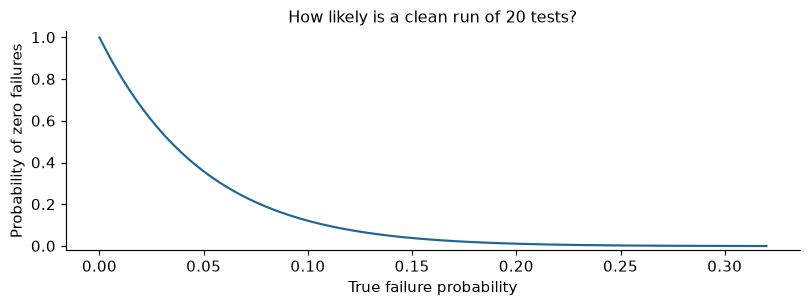

In [12]:
explore(prior_plot, [20, 50, 200], start=20, label='Tests per dataset', preview=failure_data)

*Answer:*

## 4. What does a missed confidence interval look like?

Compare 95% intervals for a population mean when the variance is unknown. Both methods use the sample standard deviation $S$. One uses 1.96 and the other uses a Student $t$ quantile.

1. Write both intervals. Which has exact 95% coverage for Gaussian data? Define coverage in terms of repeated samples.
2. At $n=8$, compare the same datasets down each column. Which misses does the wider interval recover? For the exponential data, which side of the mean has more misses? Predict what changes at $n=80$.

In [13]:
def mean_interval(mean, sd, n, multiplier):
    # TODO: Return the lower and upper endpoints.
    raise NotImplementedError('mean_interval')

def coverage(lo, hi, truth):
    # TODO: Return one Boolean per interval. Count endpoints as covered.
    raise NotImplementedError('coverage')

In [14]:
def measurement_data(n):
    rng = np.random.default_rng(204)
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 2.7), sharex=True, sharey=True, layout='constrained')
    for ax, law, samples in zip(axes, ['Gaussian','Exponential'],
                                [rng.normal(1,1,(6,n)), rng.exponential(1,(6,n))]):
        for j, sample in enumerate(samples, 1):
            ax.scatter(sample, np.full(n,j), marker='|', color=BLUE, s=70, alpha=.65)
        ax.axvline(1, color=INK, ls=':', label='Population mean')
        ax.set(xlabel='Measurement', yticks=range(1,7), ylim=(.4,6.6), title=f'{law}, n = {n}')
    axes[0].set_ylabel('Dataset')
    axes[1].legend(loc='upper right')
    return fig

def interval_plot(n):
    rng = np.random.default_rng(204)
    populations = [('Gaussian', rng.normal(1, 1, (R, n))),
                   ('Exponential', rng.exponential(1, (R, n)))]
    panels = []
    for row, (method, q) in enumerate([('1.96', 1.96), ('Student t', t.ppf(.975, n-1))]):
        for col, (law, x) in enumerate(populations):
            means = x.mean(axis=1)
            lo, hi = mean_interval(means, x.std(axis=1, ddof=1), n, q)
            hit = coverage(lo, hi, 1)
            panels.append((row, col, method, law, means, lo, hi, hit))
    fig, axes = plt.subplots(2, 2, figsize=(9.3, 5.7), sharex=True, sharey=True, layout='constrained')
    j = np.arange(1, 41)
    for row, col, method, law, means, lo, hi, hit in panels:
        ax = axes[row, col]
        colors = np.where(hit[:40], BLUE, ORANGE)
        ax.axhline(1, color=INK, ls='--', lw=1)
        ax.vlines(j, lo[:40], hi[:40], color=colors, lw=1.4)
        ax.scatter(j, means[:40], color=colors, s=8)
        ax.set_title(f'{law} · {method}   |   {hit.mean():.1%} cover, width {(hi-lo).mean():.2f}', fontsize=10)
        if row == 1:
            ax.set_xlabel('Dataset number')
        if col == 0:
            ax.set_ylabel('Interval for the mean')
    fig.suptitle(f'First 40 intervals at n = {n} · orange misses the true mean of 1\n'
                 f'Coverage and mean width use all {R:,} datasets', fontsize=11)
    return fig

Explore the data now. Complete the functions above and rerun for the full experiment.


SelectionSlider(continuous_update=False, description='Measurements per dataset', options=(8, 20, 80), style=Sl…

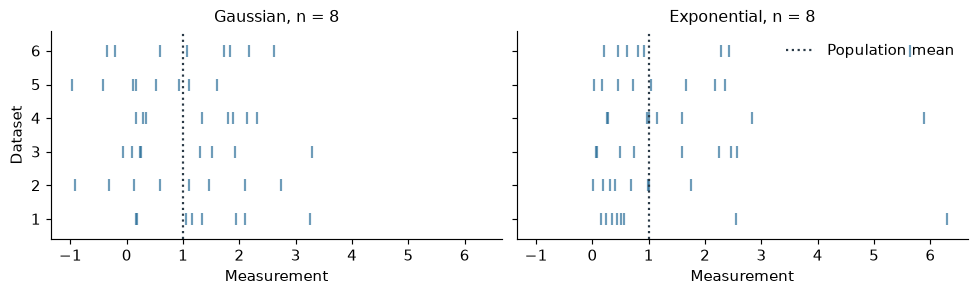

In [15]:
explore(interval_plot, [8, 20, 80], start=8, label='Measurements per dataset', preview=measurement_data)

*Answer:*

## 5. Same accuracies, different verdict?

Two classifiers answer the same 200 independent questions. Both are correct on 155, only A on 16, only B on 4, and neither on 25.

1. Assign each question a score $D_i=A_i-B_i$ and show why its mean is the accuracy gap. Build a 95% percentile bootstrap interval by resampling questions as pairs. Compare it with resampling each model independently.
2. One swap replaces a both-correct question and a both-wrong question with an A-only and a B-only success. Prove that both accuracies stay fixed. Predict which interval widens as you add swaps. Does the evidence that A is better survive?

In [16]:
def bootstrap_gap(a, b, i, j, paired):
    # i and j contain independent resampled question indices, one dataset per row.
    # TODO: Return one accuracy gap per row. Keep the pairing when requested.
    raise NotImplementedError('bootstrap_gap')

In [17]:
def pair_counts(swaps):
    return np.array([155-swaps, 16+swaps, 4+swaps, 25-swaps])

def draw_outcomes(ax, counts):
    matrix = counts.reshape(2, 2)
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=155)
    for (row, col), count in np.ndenumerate(matrix):
        ax.text(col, row, str(count), ha='center', va='center', fontsize=14,
                color='white' if count>80 else INK)
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=['B right','B wrong'],
           yticklabels=['A right','A wrong'], title='Outcomes on the same questions')

def classifier_data(swaps):
    fig, ax = plt.subplots(figsize=(4.2,3), layout='constrained')
    draw_outcomes(ax, pair_counts(swaps))
    return fig

def pairing_plot(swaps):
    counts = pair_counts(swaps)
    a, b = np.repeat([[1,1], [1,0], [0,1], [0,0]], counts, axis=0).T
    rng = np.random.default_rng(205)
    i, j = rng.integers(200, size=(2, R, 200))
    results = [(name, color, 100*bootstrap_gap(a, b, i, j, paired))
               for name, color, paired in [('Paired', BLUE, True), ('Independent', ORANGE, False)]]
    fig, (pairs, spread) = plt.subplots(1, 2, figsize=(9.2, 3.6), layout='constrained')
    draw_outcomes(pairs, counts)
    for name, color, gaps in results:
        # Integer ticks represent the possible half-percentage-point gaps.
        levels, freq = np.unique(np.rint(2*gaps)/2, return_counts=True)
        lo, hi = np.quantile(gaps, [.025, .975])
        spread.plot(levels, freq/R, color=color, label=f'{name}  [{lo:.1f}, {hi:.1f}]')
        spread.axvspan(lo, hi, color=color, alpha=.08)
    spread.axvline(0, color=INK, ls=':', label='No difference')
    spread.set(xlabel='Accuracy A minus B (percentage points)', ylabel='Bootstrap probability',
               title='Resampled gaps and 95% intervals', xlim=(-14, 26))
    spread.legend(fontsize=8)
    return fig

Explore the data now. Complete the functions above and rerun for the full experiment.


SelectionSlider(continuous_update=False, description='Swaps', options=(0, 5, 10, 15, 20, 25), style=SliderStyl…

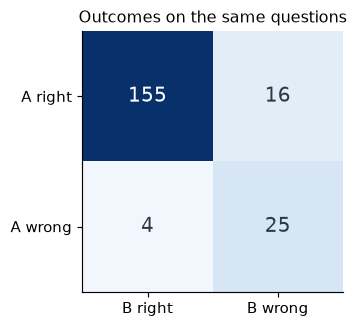

In [18]:
explore(pairing_plot, [0, 5, 10, 15, 20, 25], start=0, label='Swaps', preview=classifier_data)

*Answer:*

## 6. Which teachers can a one-parameter student imitate?

At two equally common inputs $x=1,2$, the teacher gives class 1 probabilities $(0.80,0.60)$. The student's probability is $q_x=1/(1+e^{-ax})$ with $a>0$.

1. Eliminate $a$ to express $q_2$ in terms of $q_1$. Which second probability must a teacher have to be exactly reachable when its first probability is 0.80?
2. Implement the mean binary cross-entropy and fit $a$ on the grid. Explain why the same fit minimizes forward KL. Move the teacher onto the student's curve. What happens to the fitted probabilities, the minimum KL, and the predicted labels?

In [19]:
def distillation_loss(teacher, student):
    # TODO: Mean binary cross-entropy across the two inputs, in nats.
    raise NotImplementedError('distillation_loss')

def fit_student(teacher, grid, x):
    # TODO: Evaluate your loss at every a in grid. Return the best a and all losses.
    raise NotImplementedError('fit_student')

In [20]:
def draw_models(ax, grid, teacher):
    ax.plot(expit(grid), expit(2*grid), color=BLUE, label='Reachable probabilities')
    ax.scatter(*teacher, marker='*', s=145, color=ORANGE, label='Teacher', zorder=4)
    ax.set(xlim=(.47, 1.01), ylim=(.47, 1.02), aspect='equal',
           xlabel='P(class 1 | x = 1)', ylabel='P(class 1 | x = 2)', title='Each point is one model')

def teacher_data(second):
    fig, ax = plt.subplots(figsize=(4.4,3.6), layout='constrained')
    draw_models(ax, np.linspace(.001,3,601), [.8,second])
    ax.legend(loc='lower right', fontsize=8)
    return fig

def teacher_plot(second):
    x = np.array([1, 2])
    teacher = np.array([.80, second])
    grid = np.linspace(.001, 3, 601)
    best, losses = fit_student(teacher, grid, x)
    fit = expit(best*x)
    kl = losses - distillation_loss(teacher, teacher)
    fig, (space, loss) = plt.subplots(1, 2, figsize=(9.2, 3.6), layout='constrained')
    draw_models(space, grid, teacher)
    space.plot([fit[0], teacher[0]], [fit[1], teacher[1]], ':', color=INK)
    space.scatter(*fit, facecolors='none', edgecolors=INK, s=175, lw=1.7, label='Best student', zorder=5)
    space.legend(fontsize=8, loc='lower right')
    loss.plot(grid, kl, color=BLUE)
    loss.scatter(best, kl.min(), color=ORANGE, zorder=3)
    loss.set(xlabel='Student parameter a', ylabel='Mean forward KL (nats)',
             title=f'Fit ({fit[0]:.3f}, {fit[1]:.3f}) at a = {best:.3f}')
    loss.axhline(0, ls=':', color=INK, lw=1)
    return fig

Explore the data now. Complete the functions above and rerun for the full experiment.


SelectionSlider(continuous_update=False, description='Teacher P(1 | x = 2)', options=(('0.60', 0.6), ('0.80', …

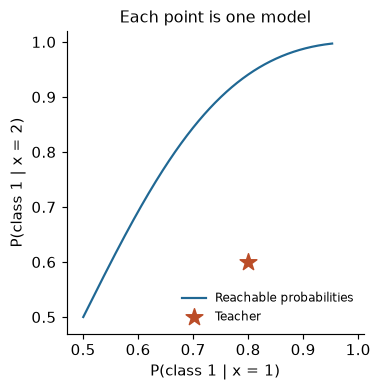

In [21]:
explore(teacher_plot, [('0.60', .60), ('0.80', .80), ('16/17', 16/17), ('0.98', .98)], start=.60, label='Teacher P(1 | x = 2)', preview=teacher_data)

*Answer:*

## 7. How much weight should each detector get?

Independent detectors count events at a common rate $\lambda$, with $X_i\sim\mathrm{Poisson}(\lambda t_i)$. They share ten minutes of observation time. Estimate $\lambda$ by $wX_1/t_1+(1-w)X_2/t_2$.

1. Derive the variance as a function of $w$ and find its minimizer. From the joint log-likelihood, derive the Fisher information and the Cramér–Rao bound. Does the optimal weight attain it?
2. Give the first detector one minute. Predict where the variance curve bottoms out, then check it at five and nine minutes. Why does the minimum stay at the same height? When does equal weighting attain it?

In [22]:
def weighted_rate(x1, x2, t1, t2, w):
    # TODO: Return one combined rate per dataset.
    raise NotImplementedError('weighted_rate')

def optimal_weight(t1, t2):
    # TODO: Return the variance-minimizing weight on detector 1.
    raise NotImplementedError('optimal_weight')

def variance_bound(rate, t1, t2):
    # TODO: Return the lower bound for an unbiased estimator.
    raise NotImplementedError('variance_bound')

In [23]:
def detector_data(t1):
    rng = np.random.default_rng(207)
    # Given the ten-minute count, event times are uniform over those ten minutes.
    events = np.sort(rng.uniform(0, 10, rng.poisson(30)))
    fig, ax = plt.subplots(figsize=(7.6,2.6), layout='constrained')
    for row, times, color in [(1,events[events<t1],BLUE), (0,events[events>=t1],ORANGE)]:
        ax.scatter(times, np.full(len(times),row), marker='|', s=180, color=color)
    ax.axvline(t1, color=INK, ls=':', label='Switch detectors')
    ax.set(xlabel='Minutes elapsed', yticks=[0,1], yticklabels=['Detector 2','Detector 1'],
           xlim=(0,10), ylim=(-.6,1.6), title='One ten-minute observation')
    ax.legend(fontsize=8)
    return fig

def detector_plot(t1):
    t2, rate = 10-t1, 3
    rng = np.random.default_rng(207)
    x1, x2 = rng.poisson(rate*t1, R), rng.poisson(rate*t2, R)
    w_star = optimal_weight(t1, t2)
    bound = variance_bound(rate, t1, t2)
    weights = np.linspace(0, 1, 101)
    variances = [weighted_rate(x1, x2, t1, t2, w).var(ddof=1) for w in weights]
    fig, ax = plt.subplots(figsize=(7.6, 3.35), layout='constrained')
    ax.plot(weights, variances, color=BLUE, label='Simulated variance')
    ax.axhline(bound, color=INK, ls=':', label=f'Variance bound: {bound:.2f}')
    for w, name, marker, color, size in [(.5, 'Equal weight', 'o', ORANGE, 95),
                                        (w_star, 'Derived optimum', 'x', INK, 64)]:
        v = weighted_rate(x1, x2, t1, t2, w).var(ddof=1)
        ax.scatter(w, v, marker=marker, color=color, s=size, zorder=4, label=f'{name} (w = {w:g})')
    ax.set(xlabel='Weight on detector 1', ylabel='Variance of estimated rate', xlim=(-.02,1.02),
           ylim=(0,3.35), title=f'Detector 1: {t1} min     ·     Detector 2: {t2} min')
    ax.legend(fontsize=9)
    return fig

Explore the data now. Complete the functions above and rerun for the full experiment.


SelectionSlider(continuous_update=False, description='Minutes on detector 1', options=(1, 2, 3, 4, 5, 6, 7, 8,…

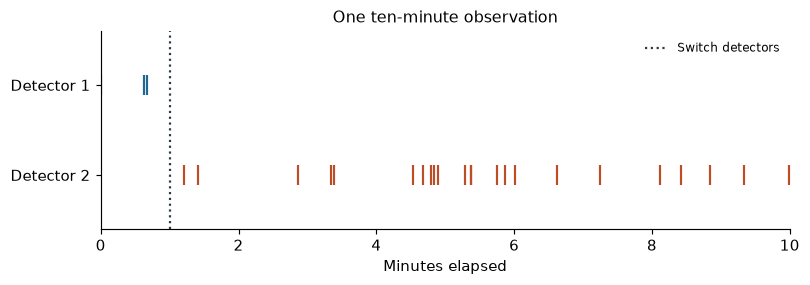

In [24]:
explore(detector_plot, [1, 2, 3, 4, 5, 6, 7, 8, 9], start=1, label='Minutes on detector 1', preview=detector_data)

*Answer:*